In [77]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans
from IPython.display import display
import seaborn as sns 


In [78]:
#load and select data

# works from the project folder or file folder
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

markets = pd.read_parquet(
    ROOT / "data" / "eda" / "20260916_v2" / "markets.parquet"
)

candidate_features = [
    "observed_wallet_count",
    "wallet_trade_count",
    "account_activity_per_observed_day",
    "mean_wallet_trade_notional",
    "wallet_activity_hhi",
    "forecast_certainty",
    "price_movement_pp_per_hour",
]

# set threshold for min number of price intervals
MIN_PRICE_INTERVALS = 6

# remove  markets without metrics for all features
complete = (
    markets[candidate_features].notna().all(axis=1)
    & markets["usable_price_intervals"].ge(MIN_PRICE_INTERVALS)
)

# remove  markets without metrics for all features

# create a copy of just the numeric features for scaling
X_candidates_raw = (
    markets.loc[complete, candidate_features]
    .astype(float)
    .copy()
)

# metadata for the markets included in the analysis
metadata = markets.loc[
    complete,
    [
        "market_id",
        "topic",
        "question",
        "window_hours",
        "usable_price_intervals",
        "price_movement_observed_hours",
    ],
].copy()

print(f"Included markets: {len(X_candidates_raw)} of {len(markets)}")
print(f"Candidate table shape: {X_candidates_raw.shape}")

display(metadata["topic"].value_counts())

Included markets: 492 of 565
Candidate table shape: (492, 7)


topic
Politics     197
Economics    164
Sports       131
Name: count, dtype: int64

In [79]:
# standardize 

candidate_log_features = [
    "observed_wallet_count",
    "wallet_trade_count",
    "account_activity_per_observed_day",
    "mean_wallet_trade_notional",
    "price_movement_pp_per_hour",
]

X_candidates_transformed = X_candidates_raw.copy()
X_candidates_transformed[candidate_log_features] = np.log1p(X_candidates_raw[candidate_log_features])

candidate_scaler = StandardScaler()


X_candidates_scaled = pd.DataFrame(
    candidate_scaler.fit_transform(X_candidates_transformed),
    columns=candidate_features,
    index=X_candidates_transformed.index,
)

# X_candidates_scaled.head()


# confirm that the scaling worked 
confirm_scale = pd.DataFrame({
    "mean": X_candidates_scaled.mean(),
    "standard_deviation": X_candidates_scaled.std(ddof=0),
})

confirm_scale.round(6)

,mean,standard_deviation
observed_wallet_count,0.0,1.0
wallet_trade_count,0.0,1.0
account_activity_per_observed_day,-0.0,1.0
mean_wallet_trade_notional,0.0,1.0
wallet_activity_hhi,-0.0,1.0
forecast_certainty,0.0,1.0
price_movement_pp_per_hour,0.0,1.0


wallet concentration, price momvement, have right skew. forecast certainty is skewed left

In [80]:
features = [
    feature
    for feature in candidate_features
]

# only include the final feature and re-transform/scale 
X_raw = X_candidates_raw[features].copy()
X_transformed = X_candidates_transformed[features].copy()

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_transformed),
    columns=features,
    index=X_transformed.index,
)

print(f"Final model input shape: {X_scaled.shape}")
display(X_scaled.head())

Final model input shape: (492, 7)


,observed_wallet_count,wallet_trade_count,account_activity_per_observed_day,mean_wallet_trade_notional,wallet_activity_hhi,forecast_certainty,price_movement_pp_per_hour
0,1.807076,1.831758,1.390694,0.465563,-1.095745,-0.644021,0.842091
1,-1.662721,-1.798606,-1.719523,-0.900245,3.051295,0.686536,0.904476
2,0.370093,0.275606,-0.287173,-0.790753,-0.529489,0.810446,-0.618452
3,0.980678,1.477123,1.075169,0.308907,0.219253,0.857650,-0.824304
4,0.972839,1.580200,0.857481,-0.287237,-0.467548,0.887152,-0.897938


In [81]:
# fit all components 
pca = PCA()
Z = pca.fit_transform(X_scaled)

# eigenvector directions
#print(pca.components_)

# fraction of total var explained by each 
#print(pca.explained_variance_ratio_)

# running portion of total variance explained
print(np.cumsum(pca.explained_variance_ratio_))

[0.53593409 0.74967148 0.87895892 0.95258663 0.9925216  0.99751185
 1.        ]


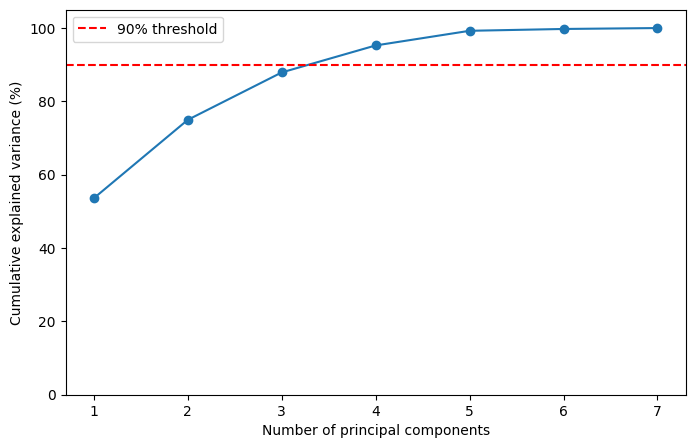

Components needed to explain at least 90%: 4


In [7]:
# plot cumulative var explained 

cumulative = np.cumsum(pca.explained_variance_ratio_)
components = np.arange(1, len(cumulative) + 1)

plt.figure(figsize=(8, 5))
plt.plot(components, cumulative * 100, marker="o")
plt.axhline(90, color="red", linestyle="--", label="90% threshold")

plt.xticks(components)
plt.ylim(0, 105)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance (%)")

plt.legend()
plt.show()

n_keep = np.argmax(cumulative >= 0.90) + 1
print(f"Components needed to explain at least 90%: {n_keep}")

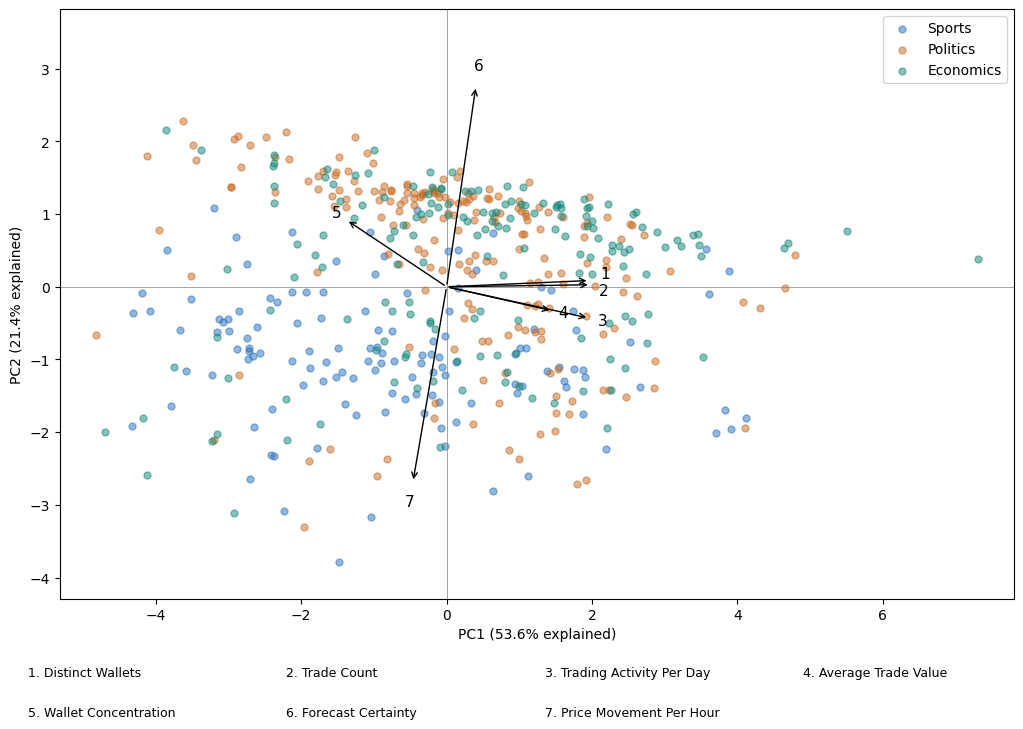

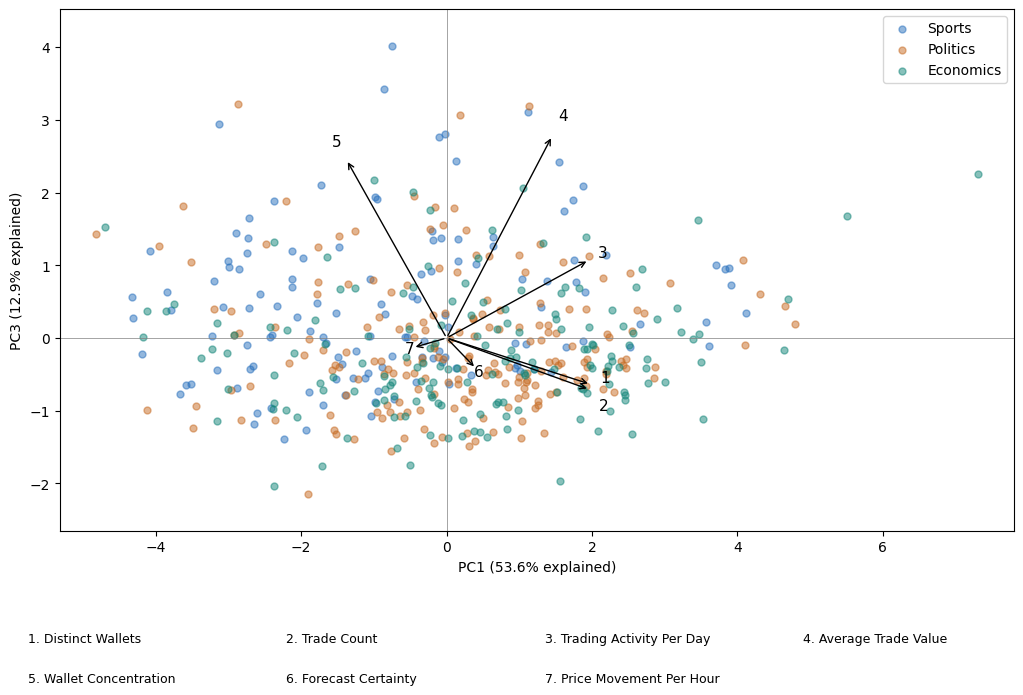

In [9]:
topic_colors = {
    "Sports": "#2870BD",
    "Politics": "#C66B23",
    "Economics": "#128578"
}

feature_names = [
    "Distinct Wallets",
    "Trade Count",
    "Trading Activity Per Day",
    "Average Trade Value",
    "Wallet Concentration",
    "Forecast Certainty",
    "Price Movement Per Hour"
]

topics = metadata.loc[X_scaled.index, "topic"].to_numpy()
weights = pca.components_.T
variance = pca.explained_variance_ratio_ * 100

ARROW_SCALE = 4

for x, y in [(0, 1), (0, 2)]:
    fig, ax = plt.subplots(figsize=(11, 8))

    # use color to seperate topics
    for topic, color in topic_colors.items():
        mask = topics == topic
        ax.scatter(
            Z[mask, x], Z[mask, y],
            color=color, label=topic, alpha=0.5, s=25
        )

    # annotate arrows and feature names; extend arrow length for viz purposes 
    arrow_tips = weights[:, [x, y]] * ARROW_SCALE

    for i, (dx, dy) in enumerate(arrow_tips):
        ax.annotate(
            "", xy=(dx, dy), xytext=(0, 0),
            arrowprops=dict(arrowstyle="->", color="black")
        )
        # Separate the two nearly parallel participation labels.
        label_offset = (0, 8 if i == 0 else -8) if i in (0, 1) else (0, 0)
        ax.annotate(
            str(i + 1), xy=(dx * 1.1, dy * 1.1),
            xytext=label_offset, textcoords="offset points",
            fontsize=11, ha="center", va="center"
        )

    # keep all items in the plotting area
    all_points = np.vstack([Z[:, [x, y]], arrow_tips * 1.2])

    ax.set_xlim(
        all_points[:, 0].min() - 0.5,
        all_points[:, 0].max() + 0.5
    )
    ax.set_ylim(
        all_points[:, 1].min() - 0.5,
        all_points[:, 1].max() + 0.5
    )

    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)
    ax.set_xlabel(f"PC{x + 1} ({variance[x]:.1f}% explained)")
    ax.set_ylabel(f"PC{y + 1} ({variance[y]:.1f}% explained)")

    ax.set_aspect("equal", adjustable="box")
    ax.legend()

    # add space for the key at the bottom; space uniformly 
    fig.tight_layout(rect=[0.03, 0.16, 0.97, 0.97])

    for i, name in enumerate(feature_names):
        column = i % 4
        row = i // 4
        fig.text(
            0.06 + column * 0.235,
            0.10 - row * 0.05,
            f"{i + 1}. {name}",
            fontsize=9,
            ha="left"
        )

    plt.show()

In [84]:
# get loadings 1 thru 4
comp_loadings = pd.DataFrame(
    pca.components_[:4].T * np.sqrt(pca.explained_variance_[:4]),
    index=feature_names,
    columns=["PC1", "PC2", "PC3", "PC4"]
)

# get max for color calibration 
limit = comp_loadings.abs().to_numpy().max()

# add heat map
display(
    comp_loadings.style
    .format("{:.2f}")
    .background_gradient(
        cmap="RdBu_r",
        axis=None,
        vmin=-limit,
        vmax=limit
    )
)

,PC1,PC2,PC3,PC4
Distinct Wallets,0.96,0.01,-0.15,0.05
Trade Count,0.95,0.03,-0.17,0.05
Trading Activity Per Day,0.95,-0.13,0.26,0.04
Average Trade Value,0.70,-0.10,0.66,-0.02
Wallet Concentration,-0.67,0.28,0.58,0.14
Forecast Certainty,0.20,0.85,-0.10,0.46
Price Movement Per Hour,-0.22,-0.82,-0.03,0.52


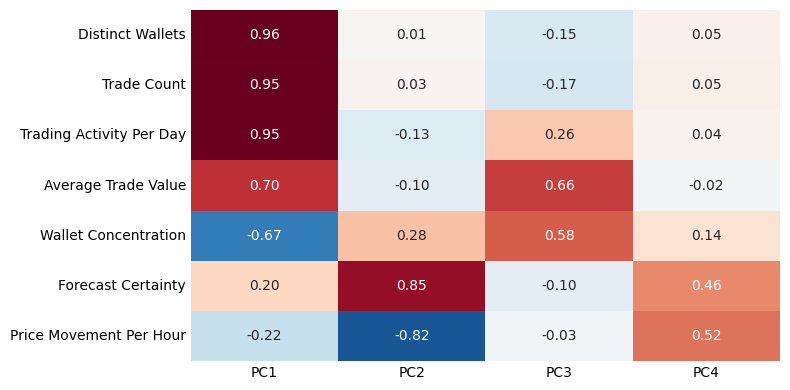

In [12]:
# visualize PCA  loadings as heatmap
limit = comp_loadings.abs().to_numpy().max()

with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(8, 4))

    sns.heatmap(
        comp_loadings,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        center=0,
        vmin=-limit,
        vmax=limit,
        cbar=False,
        linewidths=0,
        ax=ax
    )

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="both", length=0)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.grid(False)

    fig.tight_layout()

# save the figure to the figures directory
    output = ROOT/"figures"/"pca_component_loadings.png"
    output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output, dpi=300, bbox_inches="tight", facecolor="white")

    plt.show()

In [86]:
# Save current inputs and fitted results for reproducibility.
analysis_dir = ROOT / "data" / "analysis" / "20261008_wallet_trades" / "pca"
analysis_dir.mkdir(parents=True, exist_ok=True)
X_raw.to_csv(analysis_dir / "input_raw.csv", index=False)
X_scaled.to_csv(analysis_dir / "input_scaled.csv", index=False)
metadata.to_csv(analysis_dir / "market_metadata.csv", index=False)
pc_names = [f"PC{i + 1}" for i in range(Z.shape[1])]
scores = pd.DataFrame(Z, index=X_scaled.index, columns=pc_names)
metadata[["market_id", "topic"]].join(scores).to_csv(analysis_dir / "scores.csv", index=False)
pd.DataFrame({
    "component": pc_names,
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "cumulative_variance_ratio": np.cumsum(pca.explained_variance_ratio_)
}).to_csv(analysis_dir / "variance.csv", index=False)
pd.DataFrame(pca.components_.T, index=features, columns=pc_names).to_csv(analysis_dir / "component_weights.csv")
print(f"Current results saved to {analysis_dir.relative_to(ROOT)}")


Current results saved to data\analysis\20261008_wallet_trades\pca


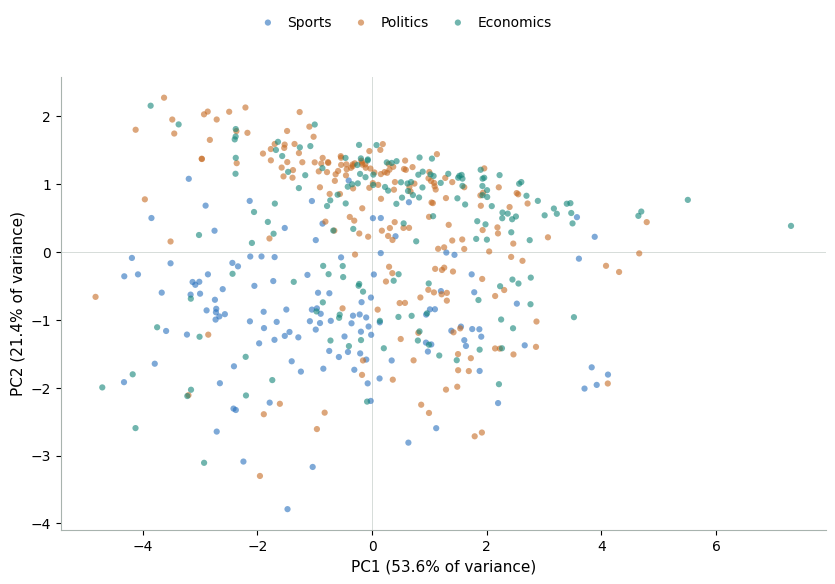

In [14]:
# markets projected onto pc1 and pc2
# colors represent marcket topics 
with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(9, 6.2), facecolor="white")
    fig.subplots_adjust(left=0.12, right=0.97, bottom=0.13, top=0.86)
    topic_colors = {"Sports": "#2870BD", "Politics": "#C66B23", "Economics": "#128578"}
    topics = metadata.loc[X_scaled.index, "topic"].to_numpy()
    variance = pca.explained_variance_ratio_ * 100
    for topic, color in topic_colors.items():
        mask = topics == topic
        ax.scatter(Z[mask, 0], Z[mask, 1], s=20, color=color, alpha=0.60,
                   edgecolors="none", label=topic)
    ax.axhline(0, color="#D6DCD9", linewidth=0.7, zorder=0)
    ax.axvline(0, color="#D6DCD9", linewidth=0.7, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["bottom", "left"]].set_color("#A8B3AE")
    ax.set_xlabel(f"PC1 ({variance[0]:.1f}% of variance)", fontsize=11)
    ax.set_ylabel(f"PC2 ({variance[1]:.1f}% of variance)", fontsize=11)
    handles, legend_labels = ax.get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="upper center", ncol=3,
               bbox_to_anchor=(0.5, 0.98), frameon=False, fontsize=10,
               handletextpad=0.4, columnspacing=1.1)
    plt.show()
